# 04 · Selección del número de segmentos (*k*)

K-Means necesita saber cuántos grupos buscar. Este notebook evalúa *k* = 2…10 con cuatro
métricas, valida el método con datos sintéticos de *k* conocido y documenta la elección.

- **Entrada:** `data/processed/lrfmc_scaled.parquet` (`uv run poe transform`).
- **Salidas:** `k_selection.csv`, `silhouette_curves.parquet` y `k_preview.csv` en
  `data/processed/` (`uv run poe select-k`).
- Código: `src/segmentacion/models/k_selection.py`. Versión web: página **Clustering**.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

from segmentacion.config import get_config
from segmentacion.features.lrfmc import LRFMC_COLUMNS
from segmentacion.models.k_selection import (
    cluster_medians,
    evaluate_k_range,
    find_elbow,
    fit_kmeans,
    silhouette_curve,
    silhouette_profile,
    stratified_sample,
)
from segmentacion.viz import model_charts as mc
from segmentacion.viz.notebook import enable_notebook_renderer

enable_notebook_renderer()
pd.set_option("display.float_format", "{:,.3f}".format)
config = get_config()
params = config.k_selection

features = pd.read_parquet(config.scaled_file)[list(LRFMC_COLUMNS)]
original = pd.read_parquet(config.lrfmc_file)[list(LRFMC_COLUMNS)]
print(f"{len(features):,} socios × {features.shape[1]} features (Yeo-Johnson + StandardScaler)")

62,044 socios × 5 features (Yeo-Johnson + StandardScaler)


## 1. ¿Funciona el método? Prueba con *k* conocido

Antes de aplicarlo a los clientes, se comprueba con 4 grupos sintéticos (`make_blobs`) que el
codo y el silhouette recuperan *k* = 4.

In [2]:
blobs, _ = make_blobs(n_samples=2_000, centers=4, n_features=5, random_state=7)
blob_table = evaluate_k_range(pd.DataFrame(blobs, columns=list(LRFMC_COLUMNS)), sample_size=1_000)
print("Codo:", find_elbow(blob_table["k"], blob_table["inertia"]))
print("Máximo silhouette:", blob_table.loc[blob_table["silhouette"].idxmax(), "k"])
blob_table.set_index("k")

Codo: 4
Máximo silhouette: 4


,inertia,silhouette,negative_pct,ch,db,min_cluster_pct
k,,,,,,
2,"171,900.437",0.566,0.000,"1,986.237",0.579,0.250
3,"38,937.137",0.752,0.000,"7,791.942",0.390,0.250
4,"9,829.839",0.785,0.000,"22,536.352",0.303,0.250
5,"9,459.258",0.613,0.004,"17,576.916",1.101,0.121
6,"9,099.956",0.436,0.026,"14,624.573",1.645,0.117
7,"8,737.057",0.326,0.036,"12,700.437",1.969,0.108
8,"8,375.341",0.143,0.051,"11,362.465",2.272,0.115
9,"8,134.375",0.141,0.042,"10,239.375",2.178,0.082
10,"7,899.118",0.134,0.046,"9,374.398",2.071,0.079


Con grupos bien separados, todas las métricas señalan *k* = 4 sin ambigüedad. Con datos de
clientes reales la señal será mucho más suave.

## 2. Métricas para *k* = 2…10

- **Inercia:** baja siempre; se busca el **codo** (punto más alejado de la recta entre los
  extremos de la curva, con ambos ejes normalizados).
- **Silhouette** (−1 a 1, ↑): sobre una muestra estratificada de 10.000 socios (es O(n²)).
  `negative_pct` = socios más cerca de otro clúster que del suyo.
- **Calinski-Harabasz** (↑) y **Davies-Bouldin** (↓).

In [3]:
table = evaluate_k_range(features, params.ks, params.silhouette_sample_size, config.random_state)
elbow = find_elbow(table["k"], table["inertia"])
print(f"Codo de la inercia: k = {elbow}")
table.set_index("k")

Codo de la inercia: k = 5


,inertia,silhouette,negative_pct,ch,db,min_cluster_pct
k,,,,,,
2,"204,440.999",0.289,0.022,"32,101.036",1.315,0.482
3,"177,899.636",0.238,0.016,"23,073.016",1.601,0.255
4,"154,773.948",0.208,0.038,"20,769.903",1.579,0.192
5,"137,269.151",0.212,0.024,"19,541.526",1.362,0.144
6,"126,456.102",0.201,0.035,"18,030.648",1.424,0.128
7,"118,282.115",0.208,0.034,"16,778.193",1.368,0.105
8,"110,754.241",0.199,0.045,"15,960.871",1.305,0.092
9,"103,788.839",0.204,0.056,"15,423.168",1.260,0.038
10,"98,581.675",0.209,0.050,"14,797.455",1.305,0.036


alt.FacetChart(...)
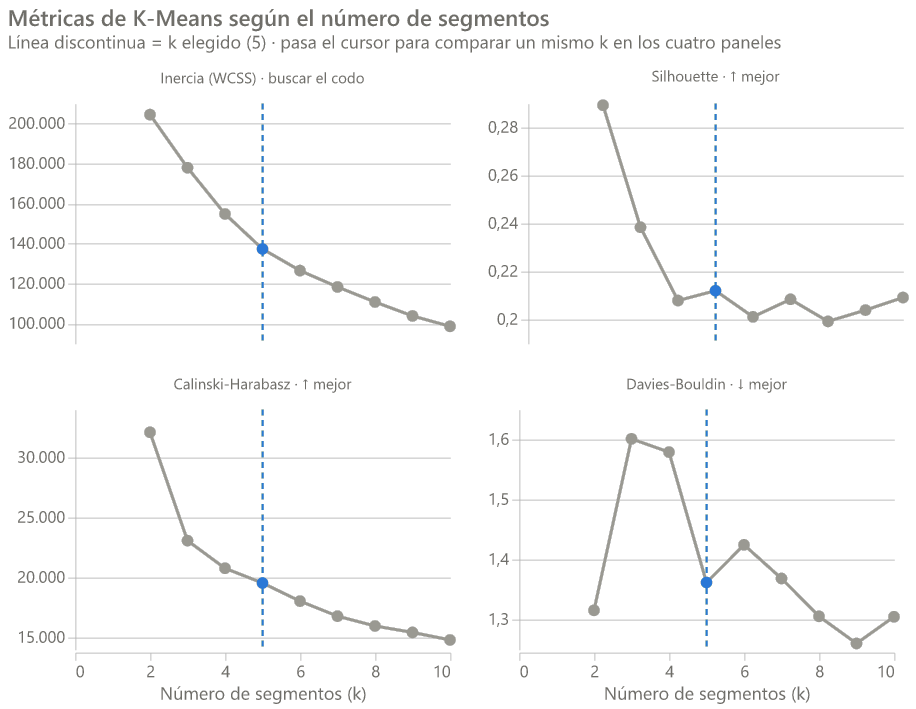

In [4]:
mc.k_metrics_chart(table.assign(elbow=table["k"] == elbow), chosen_k=params.chosen_k)

**Lectura:**

- El silhouette máximo está en *k* = 2 (activos vs inactivos), demasiado grueso para marketing.
- Entre *k* = 3 y 8 el silhouette tiene un **máximo local en *k* = 5**, donde también está el
  **codo** y un **mínimo local de Davies-Bouldin**.
- Calinski-Harabasz decrece con *k* (frecuente con grupos no esféricos): no discrimina.

## 3. ¿Es real el máximo local de *k* = 5?

Las diferencias de silhouette entre *k* = 4, 5 y 6 son de milésimas. Se repite el cálculo con
cinco muestras estratificadas distintas para ver si superan el ruido del muestreo.

In [5]:
rows = []
for k in (4, 5, 6, 7):
    labels = fit_kmeans(features, k, config.random_state).labels_
    scores = [
        silhouette_score(features.iloc[idx], labels[idx])
        for idx in (stratified_sample(labels, 10_000, seed) for seed in range(5))
    ]
    rows.append({"k": k, "silhouette_media": np.mean(scores), "desviacion": np.std(scores)})
pd.DataFrame(rows).set_index("k")

,silhouette_media,desviacion
k,,
4,0.208,0.002
5,0.213,0.001
6,0.201,0.001
7,0.208,0.002


La desviación entre muestras (~0,001) es menor que la distancia entre *k* = 5 y sus
vecinos: el máximo local es estable.

## 4. Silhouette plot

alt.LayerChart(...)
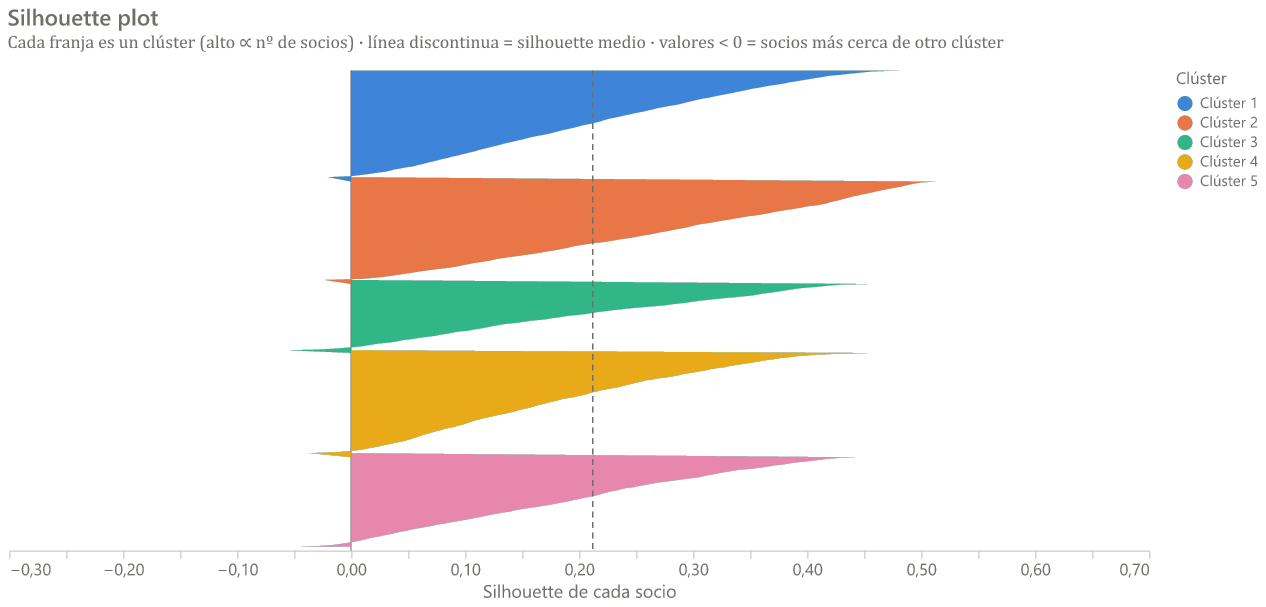

In [6]:
curves = []
for k in params.silhouette_plot_ks:
    labels = fit_kmeans(features, k, config.random_state).labels_
    profile = silhouette_profile(features, labels, params.silhouette_sample_size)
    curves.append(silhouette_curve(profile).assign(k=k))
curves = pd.concat(curves, ignore_index=True)
mc.silhouette_plot_chart(curves, chosen_k=params.chosen_k)

In [7]:
table.set_index("k").loc[3:8, ["silhouette", "negative_pct", "min_cluster_pct"]]

,silhouette,negative_pct,min_cluster_pct
k,,,
3,0.238,0.016,0.255
4,0.208,0.038,0.192
5,0.212,0.024,0.144
6,0.201,0.035,0.128
7,0.208,0.034,0.105
8,0.199,0.045,0.092


Con *k* = 5 solo el 2,4 % de los socios queda más cerca de otro clúster que del suyo, la
proporción más baja entre los *k* con 4 o más segmentos, y el clúster más pequeño reúne al
14,4 % de los socios (muy por encima del 3 % mínimo para un segmento accionable).

## 5. ¿Tienen sentido de negocio los cinco grupos?

In [8]:
labels = fit_kmeans(features, params.chosen_k, config.random_state).labels_
cluster_medians(original, labels).set_index("cluster")

,L,R,F,M,C,pct
cluster,,,,,,
0,23.589,1.933,11.000,"15,314.000",0.704,0.231
1,68.895,0.633,24.000,"34,336.500",0.741,0.213
2,28.945,8.733,3.000,"4,422.000",0.505,0.144
3,73.758,4.167,6.000,"9,131.000",0.700,0.217
4,31.704,11.467,3.000,"3,731.000",0.821,0.194


| Clúster | Lectura rápida |
|---|---|
| 0 | Socios **recientes y activos** (L ≈ 24 meses, último vuelo hace ~2 meses) |
| 1 | **Veteranos muy frecuentes** (24 vuelos, 34.000 km): el núcleo de valor |
| 2 | **Inactivos que compran barato** (> 8 meses sin volar, C ≈ 0,50) |
| 3 | **Veteranos ocasionales** (L ≈ 74 meses, 6 vuelos) |
| 4 | **Inactivos que pagan tarifa casi completa** (> 11 meses sin volar, C ≈ 0,82) |

Los dos grupos inactivos se separan por la **sensibilidad al precio** (C), algo que un ranking
por gasto no distinguiría y que lleva a acciones de reactivación distintas.

## Conclusiones

- **k = 5**: coinciden el codo, el máximo local del silhouette (estable entre muestras) y el
  mínimo local de Davies-Bouldin; es además el *k* ≥ 4 con menos socios mal asignados.
- Los cinco grupos son interpretables y ninguno baja del 14 % de los socios.
- El silhouette (0,21) supera el umbral del proyecto (≥ 0,20). Con clientes reales el
  comportamiento es un continuo y el silhouette rara vez pasa de 0,25, así que el **criterio
  principal de calidad es la estabilidad** (ARI ≥ 0,90 entre semillas), que se mide en la Fase 7.
- Siguiente paso: K-Means final, estabilidad y benchmark (notebook 05).